In [ ]:
from google.colab import userdata
import os
import subprocess
import base64

token = userdata.get("GITHUB_TOKEN")
repo = "vepaan/advanced-ml-paper-reproductions"
repo_name = repo.split("/")[-1]

# Configure authentication headers
env = os.environ.copy()
env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

try:
    if os.path.exists(repo_name):
        print(f"The directory '{repo_name}' already exists. Pulling the latest changes...")
        subprocess.run(
            ["git", "-C", "/content/advanced-ml-paper-reproductions",
            "pull", "--ff-only", "origin", "main"],
            check=True,
            env=env,
            capture_output=True,
            text=True
        )
        print("Repository updated successfully via git pull!")
    else:
        print(f"Cloning repository '{repo_name}'...")
        subprocess.run(
            ["git", "clone", f"https://github.com/{repo}.git"],
            check=True,
            env=env,
            capture_output=True,
            text=True
        )
        print("Repository cloned successfully!")
except subprocess.CalledProcessError as e:
    print("Git action failed.")
    print("Stdout:", e.stdout)
    print("Stderr:", e.stderr)
    raise e
finally:
    if 'token' in locals():
        del token
    if 'auth' in locals():
        del auth

The directory 'advanced-ml-paper-reproductions' already exists. Pulling the latest changes...
Repository updated successfully via git pull!


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
RESULTS_DIR = Path('/content/drive/MyDrive/ML-Paper-Reproductions/paper2')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_DIR = Path('/content/paper2_runs')
LOCAL_DIR.mkdir(parents=True, exist_ok=True)
print('Persistent results:', RESULTS_DIR)
print('Local runs:', LOCAL_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent results: /content/drive/MyDrive/ML-Paper-Reproductions/paper2
Local runs: /content/paper2_runs


In [ ]:
%cd /content/advanced-ml-paper-reproductions/
!pip install -r requirements.txt

/content/advanced-ml-paper-reproductions


In [ ]:
import torch

assert torch.cuda.is_available(), "CUDA GPU not available!"
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA A100-SXM4-40GB


In [ ]:
%cd /content/advanced-ml-paper-reproductions/paper2-large-batch
!git log -1 --oneline

/content/advanced-ml-paper-reproductions/paper2-large-batch
3cc837b (HEAD -> main, origin/main, origin/HEAD) paper2: support checkpoint LR refinement


In [ ]:
from pathlib import Path
import subprocess, sys

# Data must exist in the cloned repo or be downloaded here. Do not use Paper 1 preprocessing.
mnist = Path('data/mnist.npz')
if not mnist.exists():
    mnist.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(['curl', '-fL', '--retry', '3',
        'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz',
        '-o', str(mnist)], check=True)
subprocess.run([sys.executable, 'src/validate.py', '--panel', 'all', '--data'], check=True)

RUNS = [(panel, regime) for panel in ('F1','C1','C2') for regime in ('SB','LB')]
for i, (panel, regime) in enumerate(RUNS, 1):
    print(f'{i}: {panel} {regime}')

1: F1 SB
2: F1 LB
3: C1 SB
4: C1 LB
5: C2 SB
6: C2 LB


In [ ]:
import subprocess
import sys
import torch

assert torch.cuda.is_available(), "GPU not enabled!"
print("GPU:", torch.cuda.get_device_name(0), flush=True)

for panel in ["F1", "C1", "C2"]:
    for regime in ["SB", "LB"]:
        print(f"\n{'=' * 60}")
        print(f"BENCHMARK: {panel} {regime}", flush=True)
        print("=" * 60, flush=True)

        result = subprocess.run(
            [
                sys.executable, "-u", "src/train.py",
                "--mode", "benchmark",
                "--panel", panel,
                "--regime", regime,
                "--device", "cuda",
                "--bench-steps", "8",
            ],
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
        )

        print(result.stdout, flush=True)

        if result.returncode != 0:
            print(f"FAILED: {panel} {regime} (exit code {result.returncode})")
            break

GPU: NVIDIA A100-SXM4-40GB

BENCHMARK: F1 SB
RUN {'panel': 'F1', 'regime': 'SB', 'seed': 42, 'batch': 256, 'lr': 0.001, 'data': 'raw/255, no crop, no augmentation', 'architecture_version': 'independent-v1'} device cuda params 1460234
GPU NVIDIA A100-SXM4-40GB allocated 0.01 GB
{
  "panel": "F1",
  "regime": "SB",
  "steps": 8,
  "samples": 2048,
  "seconds": 0.31123874200000046,
  "samples_per_sec": 6580.157684868155,
  "batch_fetch_seconds": 0.021557168999947862,
  "train_step_seconds": 0.2894948220000515,
  "estimated_epoch_seconds_at_constant_throughput": 9.118322519531263,
  "gpu_peak_gb": 0.048
}


BENCHMARK: F1 LB
RUN {'panel': 'F1', 'regime': 'LB', 'seed': 42, 'batch': 6000, 'lr': 0.001, 'data': 'raw/255, no crop, no augmentation', 'architecture_version': 'independent-v1'} device cuda params 1460234
GPU NVIDIA A100-SXM4-40GB allocated 0.01 GB
{
  "panel": "F1",
  "regime": "LB",
  "steps": 8,
  "samples": 48000,
  "seconds": 0.7998261939999338,
  "samples_per_sec": 60013.0382826

In [ ]:
import subprocess
import sys
from pathlib import Path

assert Path("src/train.py").is_file(), "Run from paper2-large-batch/"

subprocess.run(
    [sys.executable, "-m", "py_compile", "src/train.py"],
    check=True
)

help_text = subprocess.run(
    [sys.executable, "src/train.py", "--help"],
    capture_output=True,
    text=True,
    check=True
).stdout

assert "--resume-lr" in help_text, "Updated trainer not detected!"

print("Updated trainer verified.")
print("Checkpoint resume + learning-rate adjustment ready.")

Updated trainer verified.
Checkpoint resume + learning-rate adjustment ready.


In [ ]:
import subprocess
import sys
import shutil
import time
import json
from pathlib import Path

# Run from paper2-large-batch/
LOCAL_ROOT = Path("/content/paper2_refined_lr2e4")
DRIVE_ROOT = Path("/content/drive/MyDrive/ML-Paper-Reproductions/paper2")

BASELINE_ROOT = DRIVE_ROOT / "baseline_50_epochs"
REFINED_ROOT = DRIVE_ROOT / "refined_training_lr2e4"

MAX_EPOCHS = 120
RESUME_LR = 0.0002

RUNS = [
    ("C1", "SB"),
    ("C1", "LB"),
]

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
REFINED_ROOT.mkdir(parents=True, exist_ok=True)

# Validate source checkpoints before starting.
for panel, regime in RUNS:
    name = f"{panel}_{regime}_seed42"
    baseline = BASELINE_ROOT / name

    assert (baseline / "last.pt").is_file(), f"Missing: {baseline}/last.pt"

    metrics = json.loads((baseline / "metrics.json").read_text())
    assert metrics["epoch"] == 50, f"{name}: expected epoch 50"

total_start = time.perf_counter()

for i, (panel, regime) in enumerate(RUNS, 1):
    name = f"{panel}_{regime}_seed42"

    local_dir = LOCAL_ROOT / name
    drive_dir = REFINED_ROOT / name
    baseline_dir = BASELINE_ROOT / name

    print(f"\n{'=' * 65}", flush=True)
    print(f"RUN {i}/{len(RUNS)}: {name}", flush=True)
    print(f"{'=' * 65}", flush=True)

    # Restore newest refined checkpoint when available.
    if (drive_dir / "last.pt").is_file():
        shutil.copytree(drive_dir, local_dir, dirs_exist_ok=True)
        print("Restored refined checkpoint from Drive.", flush=True)

    # Otherwise restore the original epoch-50 checkpoint.
    elif not (local_dir / "last.pt").is_file():
        shutil.copytree(baseline_dir, local_dir, dirs_exist_ok=True)
        print("Restored epoch-50 baseline from Drive.", flush=True)

    command = [
        sys.executable, "-u", "src/train.py",
        "--mode", "train",
        "--panel", panel,
        "--regime", regime,
        "--device", "cuda",
        "--max-epochs", str(MAX_EPOCHS),
        "--resume-lr", str(RESUME_LR),
        "--patience", "1000",
        "--eval-every", "5",
        "--checkpoint-every", "5",
        "--output-root", str(LOCAL_ROOT),
    ]

    start = time.perf_counter()

    try:
        subprocess.run(command, check=True)
    finally:
        # Save even if the run is interrupted or fails.
        if (local_dir / "last.pt").is_file():
            shutil.copytree(local_dir, drive_dir, dirs_exist_ok=True)
            print(f"Saved to Drive: {drive_dir}", flush=True)

    metrics = json.loads((local_dir / "metrics.json").read_text())

    print(f"\n{name} FINAL")
    print("Epoch:", metrics["epoch"])
    print("Train loss:", round(metrics["train"]["loss"], 6))
    print("Train accuracy:", round(metrics["train"]["accuracy"] * 100, 3), "%")
    print("Test accuracy:", round(metrics["test"]["accuracy"] * 100, 3), "%")

    print(
        f"{name} finished in "
        f"{(time.perf_counter() - start) / 60:.1f} minutes",
        flush=True
    )

print(f"\nTOTAL: {(time.perf_counter() - total_start) / 60:.1f} minutes")
print(f"Results: {REFINED_ROOT}")


RUN 1/2: C1_SB_seed42
Restored epoch-50 baseline from Drive.
Saved to Drive: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/refined_training_lr2e4/C1_SB_seed42

C1_SB_seed42 FINAL
Epoch: 120
Train loss: 0.001297
Train accuracy: 99.974 %
Test accuracy: 70.53 %
C1_SB_seed42 finished in 1.3 minutes

RUN 2/2: C1_LB_seed42
Restored epoch-50 baseline from Drive.
Saved to Drive: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/refined_training_lr2e4/C1_LB_seed42

C1_LB_seed42 FINAL
Epoch: 120
Train loss: 0.02128
Train accuracy: 99.676 %
Test accuracy: 66.38 %
C1_LB_seed42 finished in 1.0 minutes

TOTAL: 2.4 minutes
Results: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/refined_training_lr2e4


In [ ]:
from pathlib import Path
import shutil
import json

DRIVE = Path("/content/drive/MyDrive/ML-Paper-Reproductions/paper2")

OLD = Path("/content/paper2_selected")
NEW = Path("/content/paper2_selected_refined")

REFINED = DRIVE / "refined_training_lr2e4"

selection = {
    "F1_SB_seed42": ("current", 50),
    "F1_LB_seed42": ("current", 30),
    "C1_SB_seed42": ("refined_training_lr2e4", 120),
    "C1_LB_seed42": ("refined_training_lr2e4", 120),
    "C2_SB_seed42": ("baseline_50_epochs", 50),
    "C2_LB_seed42": ("baseline_50_epochs", 50),
}

# Validate every checkpoint before copying.
for name, (source, epoch) in selection.items():
    source_dir = (
        DRIVE / name if source == "current"
        else DRIVE / source / name
    )

    assert (source_dir / "endpoint.pt").is_file(), source_dir
    assert (source_dir / "metrics.json").is_file(), source_dir

    metrics = json.loads(
        (source_dir / "metrics.json").read_text()
    )
    assert metrics["epoch"] == epoch, (
        f"{name}: expected epoch {epoch}, got {metrics['epoch']}"
    )

assert OLD.is_dir(), "Previous selection directory missing."

NEW.mkdir(parents=True, exist_ok=True)
manifest = {}

for name, (source, epoch) in selection.items():
    source_dir = (
        DRIVE / name if source == "current"
        else DRIVE / source / name
    )

    destination = NEW / name
    destination.mkdir(parents=True, exist_ok=True)

    for filename in ("endpoint.pt", "metrics.json"):
        shutil.copy2(
            source_dir / filename,
            destination / filename
        )

    metrics = json.loads(
        (source_dir / "metrics.json").read_text()
    )

    manifest[name] = {
        "source": source,
        "epoch": epoch,
        "train_loss": metrics["train"]["loss"],
        "train_accuracy": metrics["train"]["accuracy"],
        "test_accuracy": metrics["test"]["accuracy"],
    }

    print(
        f"{name}: epoch {epoch}, "
        f"train accuracy {metrics['train']['accuracy']*100:.3f}%"
    )

# Reuse F1/C2 interpolation results: their weights are unchanged.
for panel in ("F1", "C2"):
    source = OLD / f"{panel}_interpolation.json"
    if not source.is_file():
        source = DRIVE / "final_results" / f"{panel}_interpolation.json"

    assert source.is_file(), source
    shutil.copy2(
        source,
        NEW / f"{panel}_interpolation.json"
    )

(NEW / "selection_manifest.json").write_text(
    json.dumps(manifest, indent=2)
)

print("\nSUCCESS: Refined selection prepared.")
print("Directory:", NEW)
print("C1 interpolation still needs to be computed.")

F1_SB_seed42: epoch 50, train accuracy 99.875%
F1_LB_seed42: epoch 30, train accuracy 100.000%
C1_SB_seed42: epoch 120, train accuracy 99.974%
C1_LB_seed42: epoch 120, train accuracy 99.676%
C2_SB_seed42: epoch 50, train accuracy 99.318%
C2_LB_seed42: epoch 50, train accuracy 98.250%

SUCCESS: Refined selection prepared.
Directory: /content/paper2_selected_refined
C1 interpolation still needs to be computed.


In [ ]:
from pathlib import Path
import subprocess
import sys
import shutil
import json
import time

ROOT = Path("/content/paper2_selected_refined")

DRIVE_OUT = Path(
    "/content/drive/MyDrive/ML-Paper-Reproductions/paper2/"
    "refined_interpolation"
)

assert Path("src/interpolate.py").is_file()
assert (ROOT / "C1_SB_seed42/endpoint.pt").is_file()
assert (ROOT / "C1_LB_seed42/endpoint.pt").is_file()

start = time.perf_counter()

command = [
    sys.executable, "-u", "src/interpolate.py",
    "--panel", "C1",
    "--device", "cuda",
    "--output-root", str(ROOT),
    "--points", "21",
    "--bn-policy", "recalibrate",
    "--bn-examples", "4096",
    "--eval-batch", "512",
]

print("Recomputing C1 interpolation from refined checkpoints...", flush=True)

subprocess.run(command, check=True)

result = ROOT / "C1_interpolation.json"
assert result.is_file()

data = json.loads(result.read_text())
assert len(data["points"]) == 21

DRIVE_OUT.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    result,
    DRIVE_OUT / result.name
)

shutil.copy2(
    ROOT / "selection_manifest.json",
    DRIVE_OUT / "selection_manifest.json"
)

print("\nSUCCESS: Refined C1 interpolation complete.")
print("Elapsed:", round(time.perf_counter() - start, 1), "seconds")
print("Saved:", result)
print("Drive backup:", DRIVE_OUT)

Recomputing C1 interpolation from refined checkpoints...

SUCCESS: Refined C1 interpolation complete.
Elapsed: 18.9 seconds
Saved: /content/paper2_selected_refined/C1_interpolation.json
Drive backup: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/refined_interpolation


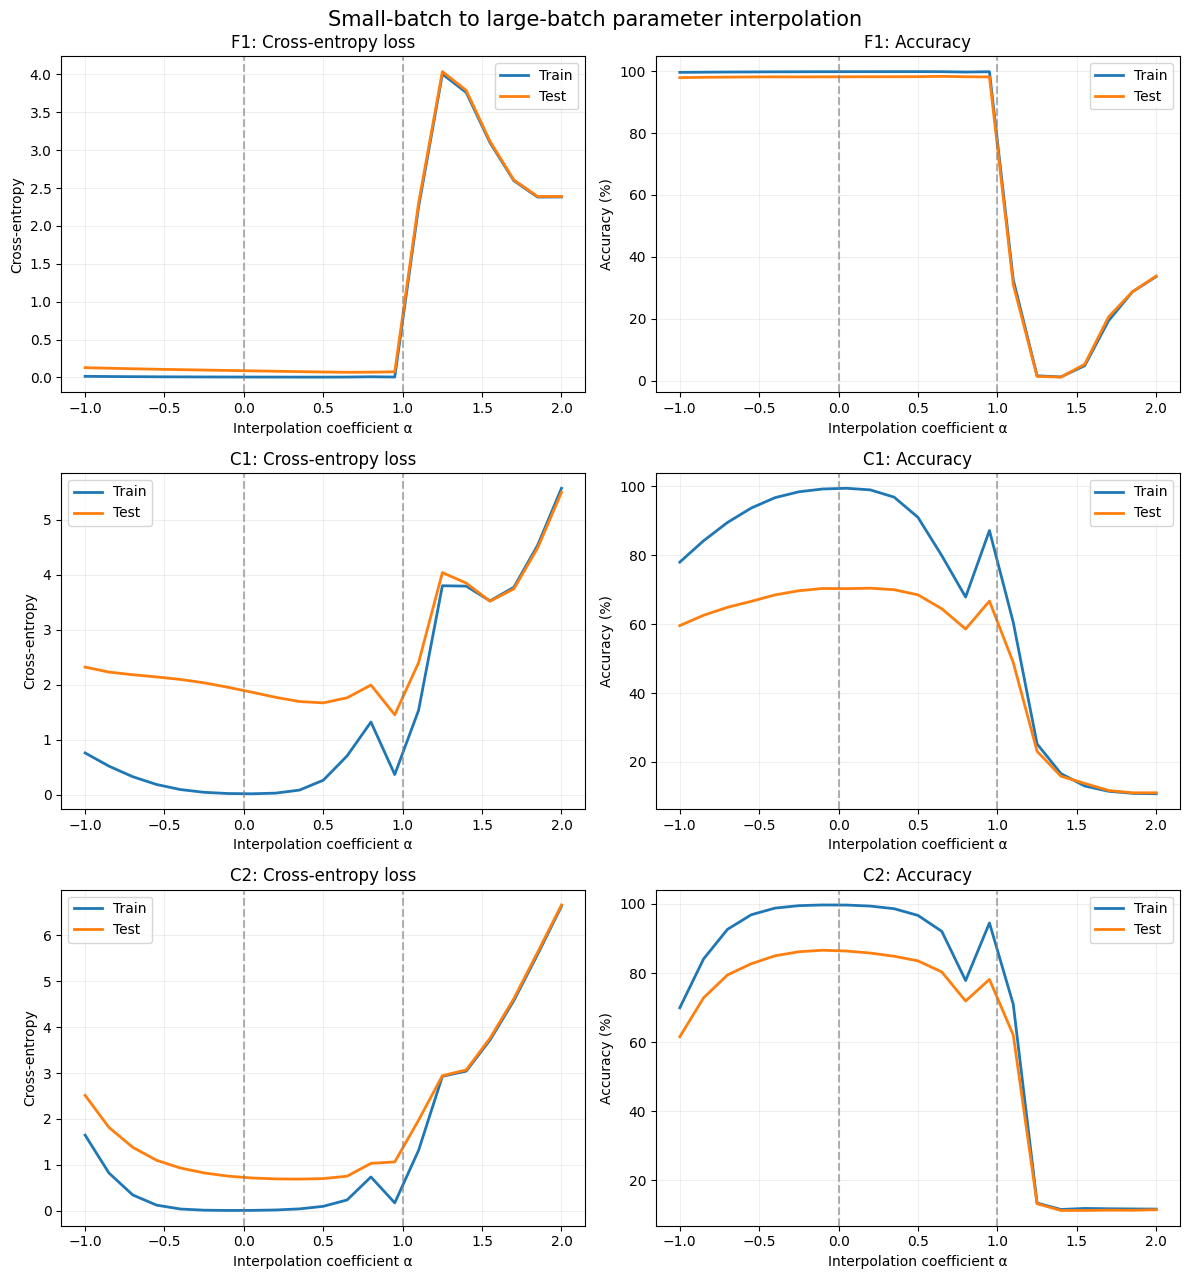

Saved: /content/paper2_final_results.zip
Drive backup: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_results


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import json, shutil
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

ROOT = Path("/content/paper2_selected")
DRIVE_FINAL = Path(
    "/content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_results"
)

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

fig, axes = plt.subplots(3, 2, figsize=(12, 13))

for i, panel in enumerate(["F1", "C1", "C2"]):
    path = ROOT / f"{panel}_interpolation.json"
    assert path.exists(), f"Missing interpolation data: {panel}"

    data = json.loads(path.read_text())
    points = data["points"]

    alpha = np.array([p["alpha"] for p in points])

    train_loss = [p["train_loss"] for p in points]
    test_loss = [p["test_loss"] for p in points]
    train_acc = [100 * p["train_accuracy"] for p in points]
    test_acc = [100 * p["test_accuracy"] for p in points]

    ax_loss, ax_acc = axes[i]

    ax_loss.plot(alpha, train_loss, label="Train", linewidth=2)
    ax_loss.plot(alpha, test_loss, label="Test", linewidth=2)
    ax_loss.set_title(f"{panel}: Cross-entropy loss")
    ax_loss.set_ylabel("Cross-entropy")

    ax_acc.plot(alpha, train_acc, label="Train", linewidth=2)
    ax_acc.plot(alpha, test_acc, label="Test", linewidth=2)
    ax_acc.set_title(f"{panel}: Accuracy")
    ax_acc.set_ylabel("Accuracy (%)")

    for ax in (ax_loss, ax_acc):
        ax.axvline(0, color="gray", linestyle="--", alpha=0.6)
        ax.axvline(1, color="gray", linestyle="--", alpha=0.6)
        ax.set_xlabel("Interpolation coefficient α")
        ax.grid(alpha=0.2)
        ax.legend()

fig.suptitle(
    "Small-batch to large-batch parameter interpolation",
    fontsize=15
)
fig.tight_layout()

png = FIGURES / "figure3_reproduction.png"
pdf = FIGURES / "figure3_reproduction.pdf"

fig.savefig(png, dpi=200, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

# Package final results only.
EXPORT = Path("/content/paper2_export")

if EXPORT.exists():
    shutil.rmtree(EXPORT)

EXPORT.mkdir()

for panel in ["F1", "C1", "C2"]:
    shutil.copy2(
        ROOT / f"{panel}_interpolation.json",
        EXPORT / f"{panel}_interpolation.json"
    )

shutil.copy2(
    ROOT / "selection_manifest.json",
    EXPORT / "selection_manifest.json"
)

shutil.copytree(FIGURES, EXPORT / "figures")

for panel in ["F1", "C1", "C2"]:
    for regime in ["SB", "LB"]:
        name = f"{panel}_{regime}_seed42"

        destination = EXPORT / "endpoints" / name
        destination.mkdir(parents=True, exist_ok=True)

        shutil.copy2(
            ROOT / name / "endpoint.pt",
            destination / "endpoint.pt"
        )

        shutil.copy2(
            ROOT / name / "metrics.json",
            destination / "metrics.json"
        )

# Back up the completed export to Drive.
shutil.copytree(EXPORT, DRIVE_FINAL, dirs_exist_ok=True)

# Create ZIP.
archive = shutil.make_archive(
    "/content/paper2_final_results",
    "zip",
    root_dir=EXPORT
)

print("Saved:", archive)
print("Drive backup:", DRIVE_FINAL)

files.download(archive)

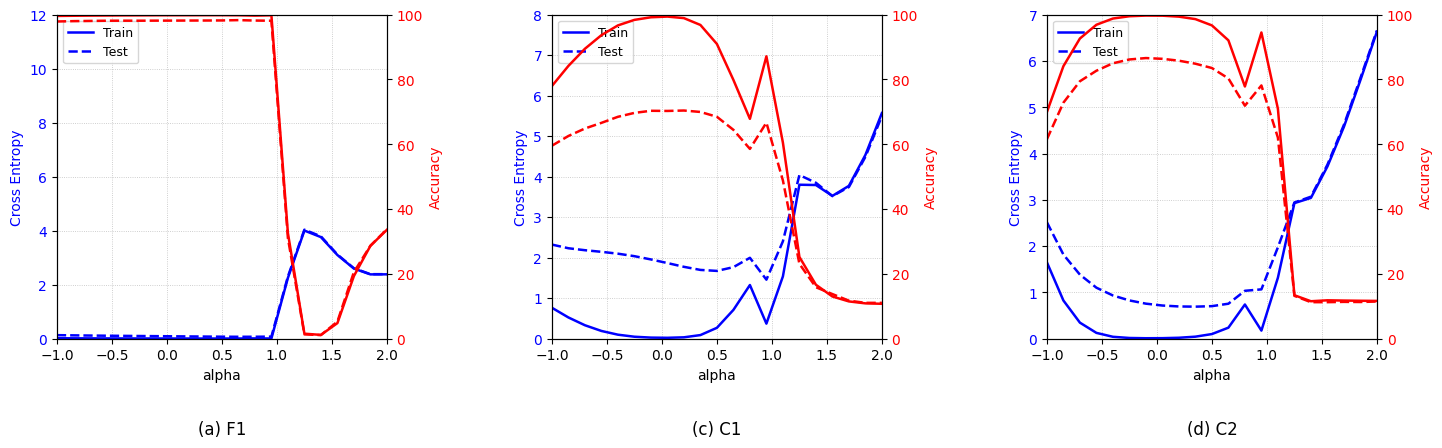

Saved locally: /content/paper2_selected/figures/figure3_F1_C1_C2.png
Saved locally: /content/paper2_selected/figures/figure3_F1_C1_C2.pdf
Backed up to: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_results


In [ ]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import shutil

# -----------------------------------------------------------
# Paths
# -----------------------------------------------------------
ROOT = Path("/content/paper2_selected")
DRIVE = Path(
    "/content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_results"
)

FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

PANELS = ["F1", "C1", "C2"]

# Original Figure 3 uses different loss-axis scales per panel.
LOSS_LIMITS = {
    "F1": (0, 12),
    "C1": (0, 8),
    "C2": (0, 7),
}

# -----------------------------------------------------------
# Reproduce the three requested Figure 3 panels
# -----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, panel in zip(axes, PANELS):

    path = ROOT / f"{panel}_interpolation.json"

    # Fall back to persistent Drive results if local files are missing.
    if not path.exists():
        path = DRIVE / f"{panel}_interpolation.json"

    assert path.is_file(), f"Missing interpolation JSON: {path}"

    data = json.loads(path.read_text())
    points = sorted(data["points"], key=lambda p: p["alpha"])

    alpha = np.array([p["alpha"] for p in points])

    train_loss = np.array([p["train_loss"] for p in points])
    test_loss = np.array([p["test_loss"] for p in points])

    train_acc = 100 * np.array(
        [p["train_accuracy"] for p in points]
    )
    test_acc = 100 * np.array(
        [p["test_accuracy"] for p in points]
    )

    # Left Y-axis: cross-entropy (blue)
    ax.plot(
        alpha, train_loss,
        color="blue", linestyle="-", linewidth=1.8,
        label="Train"
    )
    ax.plot(
        alpha, test_loss,
        color="blue", linestyle="--", linewidth=1.8,
        label="Test"
    )

    ax.set_xlim(-1, 2)
    ax.set_ylim(*LOSS_LIMITS[panel])
    ax.set_xlabel("alpha")
    ax.set_ylabel("Cross Entropy", color="blue")
    ax.tick_params(axis="y", labelcolor="blue")

    # Right Y-axis: classification accuracy (red)
    ax2 = ax.twinx()

    ax2.plot(
        alpha, train_acc,
        color="red", linestyle="-", linewidth=1.8
    )
    ax2.plot(
        alpha, test_acc,
        color="red", linestyle="--", linewidth=1.8
    )

    ax2.set_ylim(0, 100)
    ax2.set_ylabel("Accuracy", color="red")
    ax2.tick_params(axis="y", labelcolor="red")

    ax.set_xticks(np.arange(-1, 2.01, 0.5))
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.8)

    # As in the original figure:
    # alpha=0 -> SB, alpha=1 -> LB
    panel_labels = {"F1": "a", "C1": "c", "C2": "d"}

    ax.set_title(
        f"({panel_labels[panel]}) {panel}",
        y=-0.32,
        fontsize=12
    )

    ax.legend(loc="upper left", fontsize=9)

fig.subplots_adjust(
    left=0.06, right=0.94,
    bottom=0.23, top=0.95,
    wspace=0.50
)

# -----------------------------------------------------------
# Save figures
# -----------------------------------------------------------
png = FIGURES / "figure3_F1_C1_C2.png"
pdf = FIGURES / "figure3_F1_C1_C2.pdf"

fig.savefig(png, dpi=300, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

# Copy to persistent Drive
DRIVE.mkdir(parents=True, exist_ok=True)

shutil.copy2(png, DRIVE / png.name)
shutil.copy2(pdf, DRIVE / pdf.name)

print("Saved locally:", png)
print("Saved locally:", pdf)
print("Backed up to:", DRIVE)

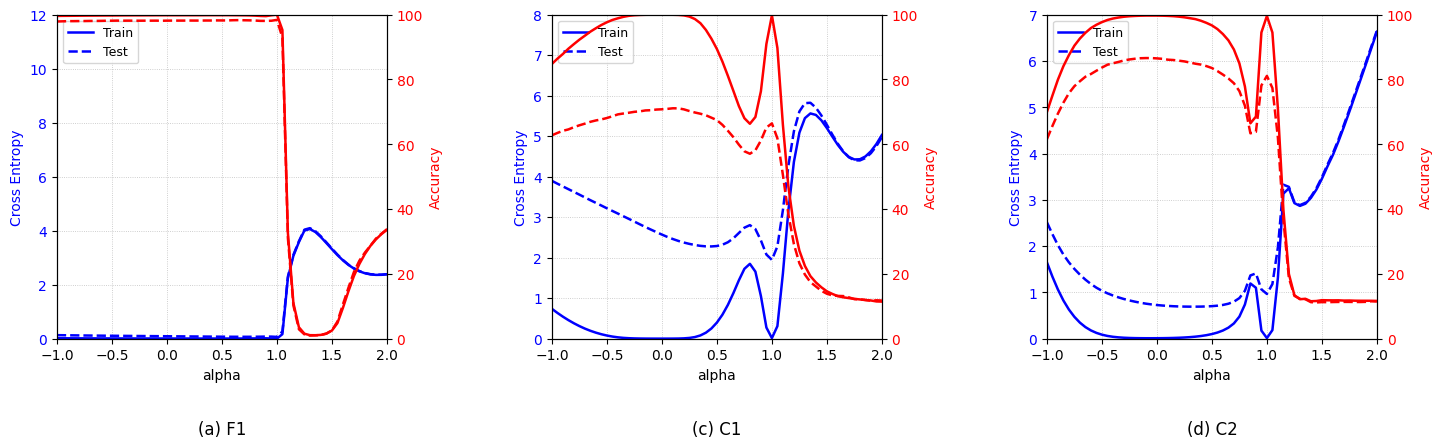

Saved locally: /content/paper2_final_61/figures/figure3_F1_C1_C2_refined.png
Saved locally: /content/paper2_final_61/figures/figure3_F1_C1_C2_refined.pdf
Backed up to: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_results


In [ ]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import shutil

# -----------------------------------------------------------
# Paths
# -----------------------------------------------------------
ROOT = Path("/content/paper2_final_61")
DRIVE = Path(
    "/content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_results"
)

FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

PANELS = ["F1", "C1", "C2"]

LOSS_LIMITS = {
    "F1": (0, 12),
    "C1": (0, 8),
    "C2": (0, 7),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

panel_labels = {"F1": "a", "C1": "c", "C2": "d"}

for ax, panel in zip(axes, PANELS):
    path = ROOT / f"{panel}_interpolation.json"
    assert path.is_file(), f"Missing interpolation JSON: {path}"

    data = json.loads(path.read_text())
    points = sorted(data["points"], key=lambda p: p["alpha"])

    alpha = np.array([p["alpha"] for p in points])
    train_loss = np.array([p["train_loss"] for p in points])
    test_loss = np.array([p["test_loss"] for p in points])
    train_acc = 100 * np.array([p["train_accuracy"] for p in points])
    test_acc = 100 * np.array([p["test_accuracy"] for p in points])

    # Left axis: cross-entropy
    ax.plot(alpha, train_loss, color="blue", linestyle="-", linewidth=1.8, label="Train")
    ax.plot(alpha, test_loss, color="blue", linestyle="--", linewidth=1.8, label="Test")
    ax.set_xlim(-1, 2)
    ax.set_ylim(*LOSS_LIMITS[panel])
    ax.set_xlabel("alpha")
    ax.set_ylabel("Cross Entropy", color="blue")
    ax.tick_params(axis="y", labelcolor="blue")
    ax.set_xticks(np.arange(-1, 2.01, 0.5))
    ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.8)

    # Right axis: accuracy
    ax2 = ax.twinx()
    ax2.plot(alpha, train_acc, color="red", linestyle="-", linewidth=1.8)
    ax2.plot(alpha, test_acc, color="red", linestyle="--", linewidth=1.8)
    ax2.set_ylim(0, 100)
    ax2.set_ylabel("Accuracy", color="red")
    ax2.tick_params(axis="y", labelcolor="red")

    ax.set_title(f"({panel_labels[panel]}) {panel}", y=-0.32, fontsize=12)
    ax.legend(loc="upper left", fontsize=9)

fig.subplots_adjust(
    left=0.06, right=0.94,
    bottom=0.23, top=0.95,
    wspace=0.50
)

png = FIGURES / "figure3_F1_C1_C2_refined.png"
pdf = FIGURES / "figure3_F1_C1_C2_refined.pdf"

fig.savefig(png, dpi=300, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")

plt.show()
plt.close(fig)

DRIVE.mkdir(parents=True, exist_ok=True)
shutil.copy2(png, DRIVE / png.name)
shutil.copy2(pdf, DRIVE / pdf.name)

print("Saved locally:", png)
print("Saved locally:", pdf)
print("Backed up to:", DRIVE)

In [ ]:
from pathlib import Path
import subprocess, sys, shutil, json, time
import numpy as np

SOURCE = Path("/content/paper2_selected_refined")
ROOT = Path("/content/paper2_final_61")

DRIVE = Path(
    "/content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_61"
)

assert Path("src/interpolate.py").is_file()
assert (SOURCE / "selection_manifest.json").is_file()

ROOT.mkdir(parents=True, exist_ok=True)
DRIVE.mkdir(parents=True, exist_ok=True)

# Preserve selected model checkpoints.
for panel in ["F1", "C1", "C2"]:
    for regime in ["SB", "LB"]:
        name = f"{panel}_{regime}_seed42"
        src = SOURCE / name
        dst = ROOT / name

        assert (src / "endpoint.pt").is_file()

        shutil.copytree(src, dst, dirs_exist_ok=True)

shutil.copy2(
    SOURCE / "selection_manifest.json",
    ROOT / "selection_manifest.json"
)

# Verify exact endpoint inclusion.
alpha = np.linspace(-1, 2, 61)
assert np.any(np.isclose(alpha, 0))
assert np.any(np.isclose(alpha, 1))

for panel in ["F1", "C1", "C2"]:

    print(f"\n{'=' * 60}")
    print(f"INTERPOLATION: {panel} — 61 points")
    print("=" * 60, flush=True)

    start = time.perf_counter()

    command = [
        sys.executable, "-u", "src/interpolate.py",
        "--panel", panel,
        "--device", "cuda",
        "--output-root", str(ROOT),
        "--points", "61",
        "--bn-policy", "recalibrate",
        "--bn-examples", "4096",
        "--eval-batch", "512",
    ]

    subprocess.run(command, check=True)

    output = ROOT / f"{panel}_interpolation.json"
    assert output.is_file()

    data = json.loads(output.read_text())
    points = data["points"]

    assert len(points) == 61

    for target in [0.0, 1.0]:
        point = next(
            p for p in points
            if abs(p["alpha"] - target) < 1e-8
        )

        print(
            f"alpha={target:.1f}: "
            f"train CE={point['train_loss']:.6f}, "
            f"train acc={point['train_accuracy']*100:.3f}%, "
            f"test acc={point['test_accuracy']*100:.3f}%"
        )

    shutil.copy2(output, DRIVE / output.name)

    print(
        f"{panel} completed in "
        f"{time.perf_counter()-start:.1f}s"
    )

shutil.copy2(
    ROOT / "selection_manifest.json",
    DRIVE / "selection_manifest.json"
)

print("\nFINAL 61-POINT INTERPOLATIONS COMPLETE")
print("Local:", ROOT)
print("Drive:", DRIVE)


INTERPOLATION: F1 — 61 points
alpha=0.0: train CE=0.005876, train acc=99.823%, test acc=98.150%
alpha=1.0: train CE=0.000174, train acc=100.000%, test acc=98.380%
F1 completed in 42.0s

INTERPOLATION: C1 — 61 points
alpha=0.0: train CE=0.000671, train acc=99.988%, test acc=70.790%
alpha=1.0: train CE=0.014134, train acc=99.794%, test acc=66.440%
C1 completed in 45.5s

INTERPOLATION: C2 — 61 points
alpha=0.0: train CE=0.009443, train acc=99.718%, test acc=86.500%
alpha=1.0: train CE=0.012536, train acc=99.610%, test acc=81.100%
C2 completed in 102.0s

FINAL 61-POINT INTERPOLATIONS COMPLETE
Local: /content/paper2_final_61
Drive: /content/drive/MyDrive/ML-Paper-Reproductions/paper2/final_61
